Video Loaded: Resolution 1280x800 | FPS: 30.00 | Delta_t: 0.0333s
Geometry Initialized: Center (np.uint16(658), np.uint16(424)), Radius 198
Detected 75 initial features within the restricted equatorial band.
Initialization complete. Found 75 features for KLT tracking.
Detected 83 initial features within the restricted equatorial band.
Detected 82 initial features within the restricted equatorial band.
Detected 78 initial features within the restricted equatorial band.
Detected 77 initial features within the restricted equatorial band.
Detected 79 initial features within the restricted equatorial band.
Detected 77 initial features within the restricted equatorial band.
Detected 78 initial features within the restricted equatorial band.
Detected 78 initial features within the restricted equatorial band.
Detected 71 initial features within the restricted equatorial band.
Detected 70 initial features within the restricted equatorial band.
Detected 74 initial features within the restricted 

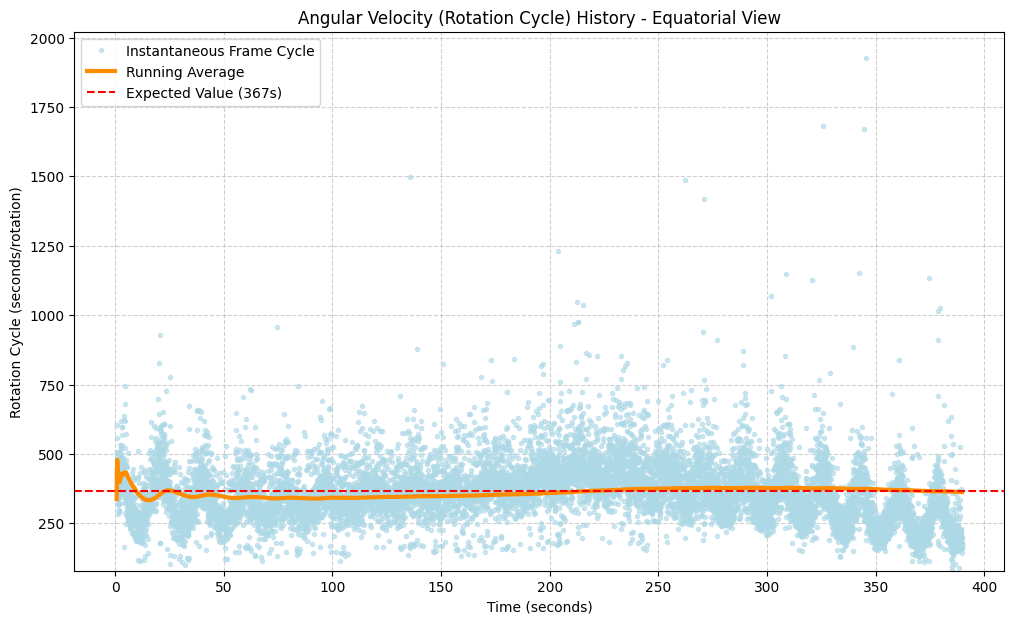

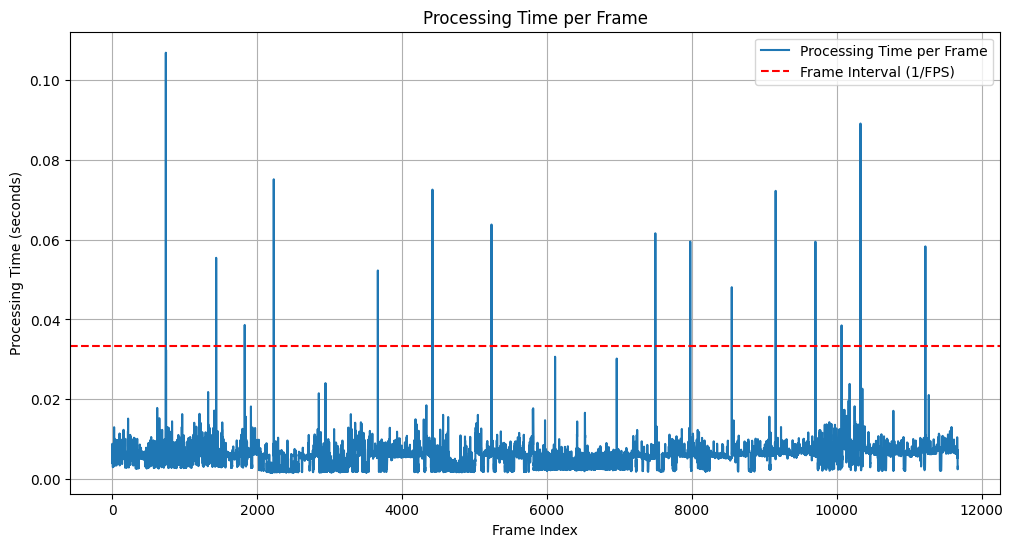

In [ ]:
"""Side view instant rotation cycle estimation with an extra plot for the processing time at each timestep"""

import cv2
import numpy as np
import time
import math
import matplotlib.pyplot as plt

VIDEO_PATH = "AO_Rotation_Recording_full3.mp4"
START_FRAME_INDEX = 20

# KLT feature detection parameters
MAX_FEATURES = 250
FEATURE_QUALITY_LEVEL = 0.001
FEATURE_MIN_DISTANCE = 10
RE_TRACK_MIN_COUNT = 50

# KLT optical flow parameters
LK_WINDOW_SIZE = (21, 21)
LK_MAX_LEVEL = 3
LK_CRITERIA = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)

# Equatorial Tracking Parameters
EQUATORIAL_BAND_HEIGHT_RATIO = 0.20
EQUATORIAL_BAND_WIDTH_RATIO = 0.80 

# Hough Circle parameters 
HOUGH_DP = 1
HOUGH_MIN_DIST = 100
HOUGH_PARAM1 = 50
HOUGH_PARAM2 = 30

# results variables
time_history = []
velocity_history = []
average_history = []
processing_times = []  

# general info
globe_center = None
globe_radius = None
fps = 0
frame_counter = 0

prev_points = None
prev_gray = None
EXPECTED_CYCLE = 367.17

def find_globe_geometry(frame):
    """
    Finds the center and radius of the globe.
    """
    if frame is None:
        return None, None

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (9, 9), 2)

    min_rad = int(frame.shape[0]*0.15)
    max_rad = int(frame.shape[0]*0.4)

    circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, HOUGH_DP, HOUGH_MIN_DIST,
                               param1=HOUGH_PARAM1, param2=HOUGH_PARAM2,
                               minRadius=min_rad, maxRadius=max_rad)
    if circles is not None:
        circles = np.uint16(np.around(circles))
        best_circle = circles[0, 0]
        center = (best_circle[0], best_circle[1])
        radius = best_circle[2]

        print(f"Geometry Initialized: Center {center}, Radius {radius}")
        return center, radius
    else:
        print("Hough Circle failed to detect the globe.")
        return None, None

def detect_initial_features_in_band(frame_gray, center, radius):
    """
    Detects strong corners and restricts them to the restricted equatorial band using a mask.
    """
    mask = np.zeros_like(frame_gray)
    cx, cy = center

    # Define the horizontal equatorial band 
    half_band_height = int(radius * EQUATORIAL_BAND_HEIGHT_RATIO / 2)
    restricted_radius = int(radius * EQUATORIAL_BAND_WIDTH_RATIO)

    rect_top_left = (cx - restricted_radius, cy - half_band_height)
    rect_bottom_right = (cx + restricted_radius, cy + half_band_height)

    # Create the rectangular mask
    cv2.rectangle(mask, rect_top_left, rect_bottom_right, 255, -1)

    # detect initial features
    points = cv2.goodFeaturesToTrack(frame_gray,
                                     maxCorners=MAX_FEATURES,
                                     qualityLevel=FEATURE_QUALITY_LEVEL,
                                     minDistance=FEATURE_MIN_DISTANCE,
                                     mask=mask)
    if points is None or len(points) < RE_TRACK_MIN_COUNT:
        return None

    print(f"Detected {len(points)} initial features.")
    return points

def calculate_angular_velocity(p0, p1, center, radius, delta_t):
    """
    Calculates the rotation cycle based on the median horizontal displacement.
    """
    if not p0.size or not p1.size or len(p0) != len(p1) or len(p0) < 5:
        return None
    p0_reshaped = p0.reshape(-1, 2)
    p1_reshaped = p1.reshape(-1, 2)
    delta_x = p1_reshaped[:, 0] - p0_reshaped[:, 0]
    median_delta_x = np.median(delta_x)

    if radius == 0:
        return None

    omega = abs(median_delta_x / delta_t / radius)

    if omega < 1e-6:
        return None

    rotation_cycle = 2 * math.pi / omega

    return rotation_cycle

def apply_geometric_filter(p_old, p_new, center, radius):
    """
    Filters tracked points to ensure they remain within the restricted equatorial tracking band.
    """
    cx, cy = center
    half_band_height = int(radius * EQUATORIAL_BAND_HEIGHT_RATIO / 2)
    restricted_radius = int(radius * EQUATORIAL_BAND_WIDTH_RATIO)

    min_y = cy - half_band_height
    max_y = cy + half_band_height

    min_x = cx - restricted_radius
    max_x = cx + restricted_radius
    p_new_flat = p_new.reshape(-1, 2)

    is_in_band_y = (p_new_flat[:, 1] >= min_y) & (p_new_flat[:, 1] <= max_y)
    is_in_band_x = (p_new_flat[:, 0] >= min_x) & (p_new_flat[:, 0] <= max_x)

    is_in_band = is_in_band_x & is_in_band_y

    filtered_p_new = p_new[is_in_band]
    filtered_p_old = p_old[is_in_band]

    return filtered_p_old, filtered_p_new

def plot_results_after_processing():
    """
    Plot the rotation cycle estimate over time
    """
    global time_history, velocity_history, average_history, EXPECTED_CYCLE
    global processing_times

    # Plot angular velocity results
    plt.figure(figsize=(12, 7))
    plt.title("Angular Velocity (Rotation Cycle) History - Equatorial View")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Rotation Cycle (seconds/rotation)")

    plt.plot(time_history, velocity_history, 'o', label='Instantaneous Frame Cycle', markersize=3,
             color='lightblue', alpha=0.6)
    plt.plot(time_history, average_history, '-', label='Running Average', linewidth=3,
             color='darkorange')
    plt.axhline(EXPECTED_CYCLE, color='red', linestyle='--', label=f'Expected Value ({EXPECTED_CYCLE:.0f}s)')

    # Calculate min/max for dynamic Y-axis limit
    data_min = min(velocity_history) * 0.95
    data_max = max(velocity_history) * 1.05
    y_min = min(data_min, EXPECTED_CYCLE * 0.95)
    y_max = max(data_max, EXPECTED_CYCLE * 1.05)
    plt.ylim(y_min, y_max)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show(block=True)

    # Plot processing times
    plt.figure(figsize=(12, 6))
    plt.plot(range(len(processing_times)), processing_times, label='Processing Time per Frame')
    plt.axhline(1/fps, color='red', linestyle='--', label='Frame Interval (1/FPS)')
    plt.title('Processing Time per Frame')
    plt.xlabel('Frame Index')
    plt.ylabel('Processing Time (seconds)')
    plt.legend()
    plt.grid(True)
    plt.show()

def process_live_video():
    """
    The main loop for KLT tracking and velocity estimation.
    """
    global globe_center, globe_radius, fps, frame_counter, prev_points, prev_gray
    global time_history, velocity_history, average_history, processing_times

    cap = cv2.VideoCapture(VIDEO_PATH)
    
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    delta_t = 1.0 / fps
    print(f"Video Loaded: Resolution {frame_width}x{frame_height} | FPS: {fps:.2f} | Delta_t: {delta_t:.4f}s")

    # find initial frame
    while frame_counter < START_FRAME_INDEX:
        ret, frame = cap.read()
        if not ret: break
        frame_counter += 1
    
    globe_center, globe_radius = find_globe_geometry(frame)
    if globe_center is None:
        cap.release()
        return

    prev_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    prev_points = detect_initial_features_in_band(prev_gray, globe_center, globe_radius)

    print(f"Initialization complete. Found {len(prev_points)} features for KLT tracking.")

    rotation_cycle_smoothed = None

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        frame_counter += 1
        # start time for processing this frame
        start_time = time.time() 
        current_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # KLT tracking and geometric ROI filtering
        current_points, status, err = cv2.calcOpticalFlowPyrLK(
            prev_gray, current_gray, prev_points, None, winSize=LK_WINDOW_SIZE,
            maxLevel=LK_MAX_LEVEL, criteria=LK_CRITERIA
        )

        good_old = prev_points[status == 1]
        good_new = current_points[status == 1]

        if good_new.size > 0:
            good_old, good_new = apply_geometric_filter(good_old, good_new, globe_center, globe_radius)

        final_inlier_count = len(good_new)

        # Check whether we need to re initialize features
        re_detect_needed = (final_inlier_count < RE_TRACK_MIN_COUNT)
        if re_detect_needed:
            new_points = detect_initial_features_in_band(current_gray, globe_center, globe_radius)
            if new_points is not None and len(new_points) >= RE_TRACK_MIN_COUNT:
                prev_points = new_points
            else:
                prev_points = good_new.reshape(-1, 1, 2) if good_new.size > 0 else np.array([])
        else:
             prev_points = good_new.reshape(-1, 1, 2)

        prev_gray = current_gray.copy()

        # angular velocity calculation
        current_time_sec = frame_counter * delta_t
        cycle_estimate = None
        if good_old.size > 0 and good_new.size > 0 and len(good_new) >= 5:
            cycle_estimate = calculate_angular_velocity(good_old, good_new, globe_center, globe_radius, delta_t)

            if cycle_estimate is not None:
                time_history.append(current_time_sec)
                velocity_history.append(cycle_estimate)
                current_avg = sum(velocity_history) / len(velocity_history)
                average_history.append(current_avg)

                if rotation_cycle_smoothed is None:
                    rotation_cycle_smoothed = cycle_estimate
                else:
                    rotation_cycle_smoothed = 0.9 * rotation_cycle_smoothed + 0.1 * cycle_estimate

        # Measure processing time for this frame
        processing_time = time.time() - start_time
        processing_times.append(processing_time)

        cycle_display = "N/A"
        if rotation_cycle_smoothed is not None:
            cycle_display = f"Smoothed Cycle: {rotation_cycle_smoothed:.2f} s/rot"

            if average_history:
                 avg_cycle_display = f"Avg Cycle: {average_history[-1]:.2f} s/rot"
                 cv2.putText(frame, avg_cycle_display, (frame_width - 320, 60), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 100, 0), 2)

            cv2.putText(frame, cycle_display, (frame_width - 320, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

        cv2.putText(frame, f"Time: {current_time_sec:.2f}s", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 0), 2)
        cv2.putText(frame, f"Active Tracks: {final_inlier_count}", (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 100, 255), 2)
        speed_check = f"Proc Time: {processing_time*1000:.2f} ms | FPS Target: {delta_t*1000:.2f} ms"
        cv2.putText(frame, speed_check, (10, frame_height - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 255), 1)
        
        # Draw the active features
        for point in good_new:
            x, y = point.ravel().astype(int)
            frame = cv2.circle(frame, (x, y), 3, (0, 255, 255), -1)

        # Draw the restricted tracking band boundaries 
        half_band_height = int(globe_radius * EQUATORIAL_BAND_HEIGHT_RATIO / 2)
        restricted_radius = int(globe_radius * EQUATORIAL_BAND_WIDTH_RATIO)
        cx, cy = globe_center
        rect_top_left = (cx - restricted_radius, cy - half_band_height)
        rect_bottom_right = (cx + restricted_radius, cy + half_band_height)
        cv2.rectangle(frame, rect_top_left, rect_bottom_right, (0, 165, 255), 1)
        cv2.imshow('KLT Optical Flow Tracker (Equatorial View)', frame)

        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

    plot_results_after_processing()

if __name__ == "__main__":
    plt.ioff()
    process_live_video()
